# SAM

In [1]:
using_colab = True
PYTORCH_NO_CUDA_MEMORY_CACHING=1

In [2]:
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/sam2.git'

    !mkdir -p images
    !wget -P images https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/cars.jpg

    !mkdir -p ../checkpoints/
    !wget -P ../checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
CUDA is available: True
  Cloning https://github.com/facebookresearch/sam2.git to /tmp/pip-req-build-rv0_pw7p
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /tmp/pip-req-build-rv0_pw7p
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--2026-04-14 15:27:02--  https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/cars.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1058188 (1.0M) [image/jpeg]
Saving to: ‘images/cars.jpg.3’

cars

In [3]:
# imports
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
# select the device for computation
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"using device: {device}")

if device.type == "cuda":
    # use bfloat16 for the entire notebook
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    # turn on tfloat32 for Ampere GPUs (https://pytorch.org/docs/stable/notes/cuda.html#tensorfloat-32-tf32-on-ampere-devices)
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
elif device.type == "mps":
    print(
        "\nSupport for MPS devices is preliminary. SAM 2 is trained with CUDA and might "
        "give numerically different outputs and sometimes degraded performance on MPS. "
        "See e.g. https://github.com/pytorch/pytorch/issues/84936 for a discussion."
    )

using device: cuda


In [5]:
np.random.seed(3)

def show_anns(anns, borders=True):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)

    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:, :, 3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.5]])
        img[m] = color_mask
        if borders:
            import cv2
            contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            # Try to smooth contours
            contours = [cv2.approxPolyDP(contour, epsilon=0.01, closed=True) for contour in contours]
            cv2.drawContours(img, contours, -1, (0, 0, 1, 0.4), thickness=1)

    ax.imshow(img)

In [6]:
image = Image.open('/content/April 13, 2026  Plate.jpg')
image = np.array(image.convert("RGB"))

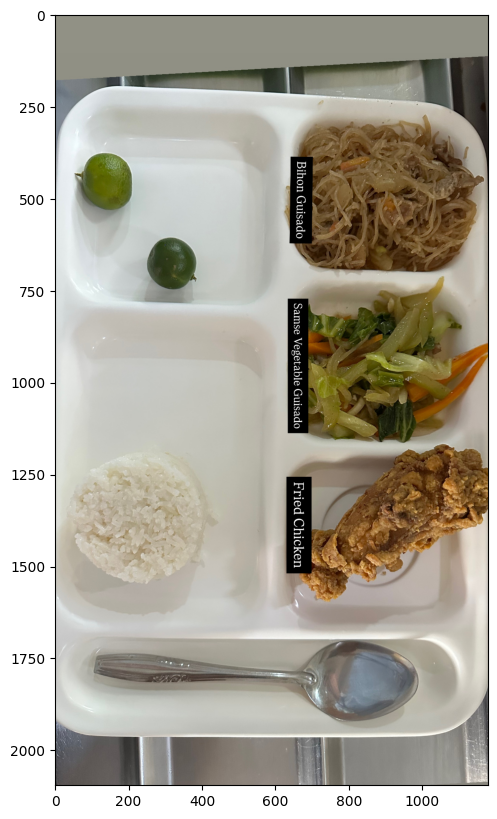

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis('on')
plt.show()

In [7]:
from sam2.build_sam import build_sam2
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

sam2_checkpoint = "../checkpoints/sam2.1_hiera_tiny.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_t.yaml"

sam2 = build_sam2(model_cfg, sam2_checkpoint, device=device, apply_postprocessing=False)

mask_generator = SAM2AutomaticMaskGenerator(sam2)

In [ ]:
# masks = mask_generator.generate(image)

In [ ]:
# print(len(masks))
# print(masks[0].keys())

19
dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


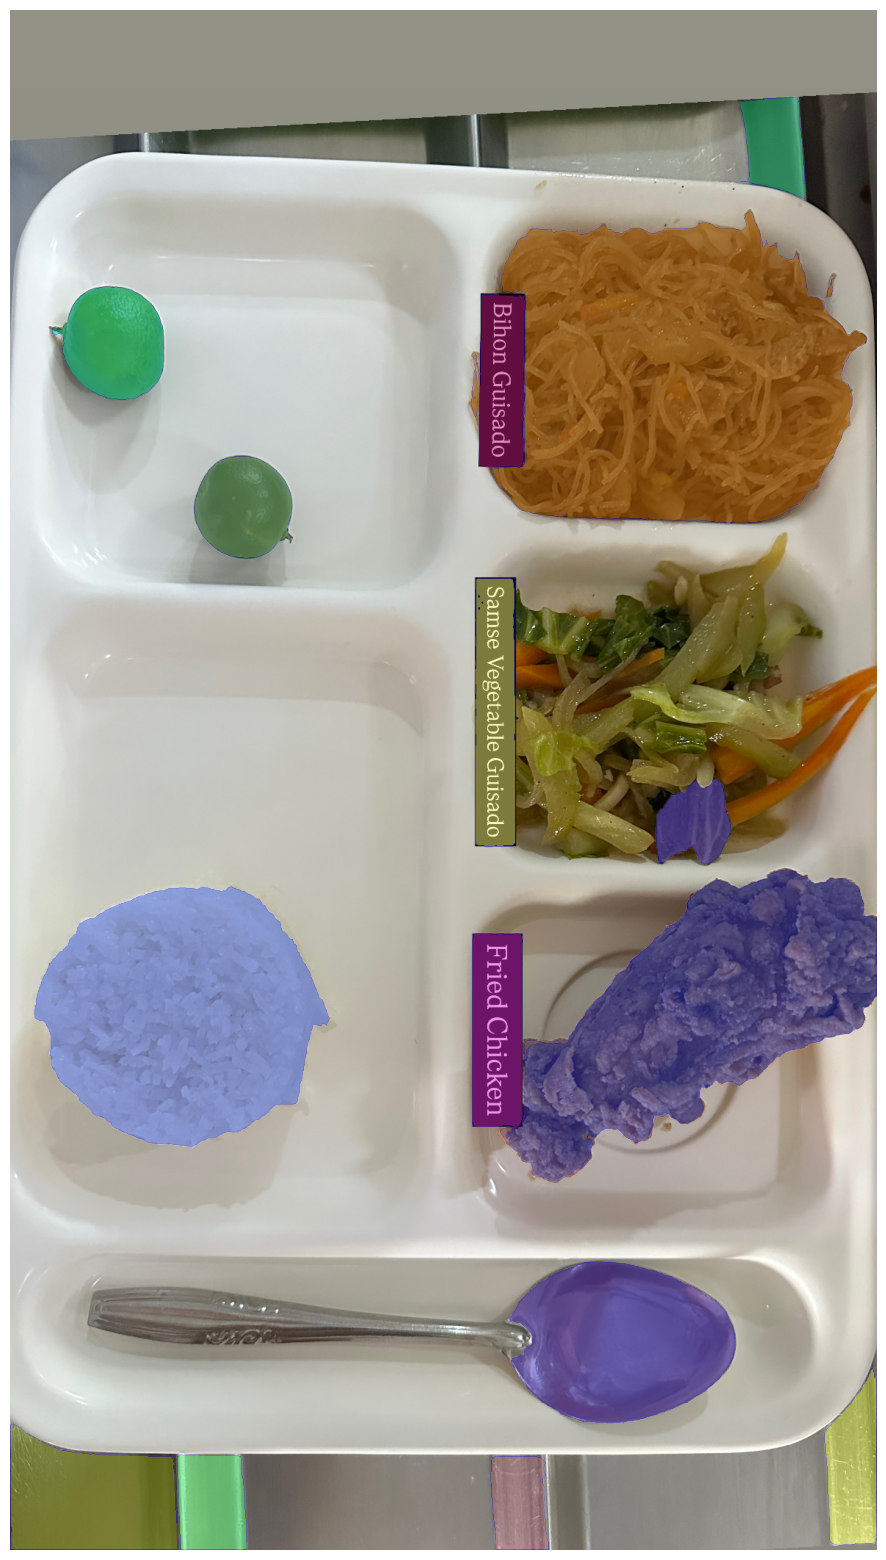

In [ ]:
# plt.figure(figsize=(20, 20))
# plt.imshow(image)
# show_anns(masks)
# plt.axis('off')
# plt.show()

In [39]:
mask_generator_2 = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,
    # points_per_batch=128,
    pred_iou_thresh=0.6,
    stability_score_thresh=0.85,
    stability_score_offset=0.83,
    # crop_n_layers=1,
    # box_nms_thresh=0.7,
    # crop_n_points_downscale_factor=2,
    # min_mask_region_area=25.0,
    # use_m2m=True,
)

In [40]:
masks2 = mask_generator_2.generate(image)

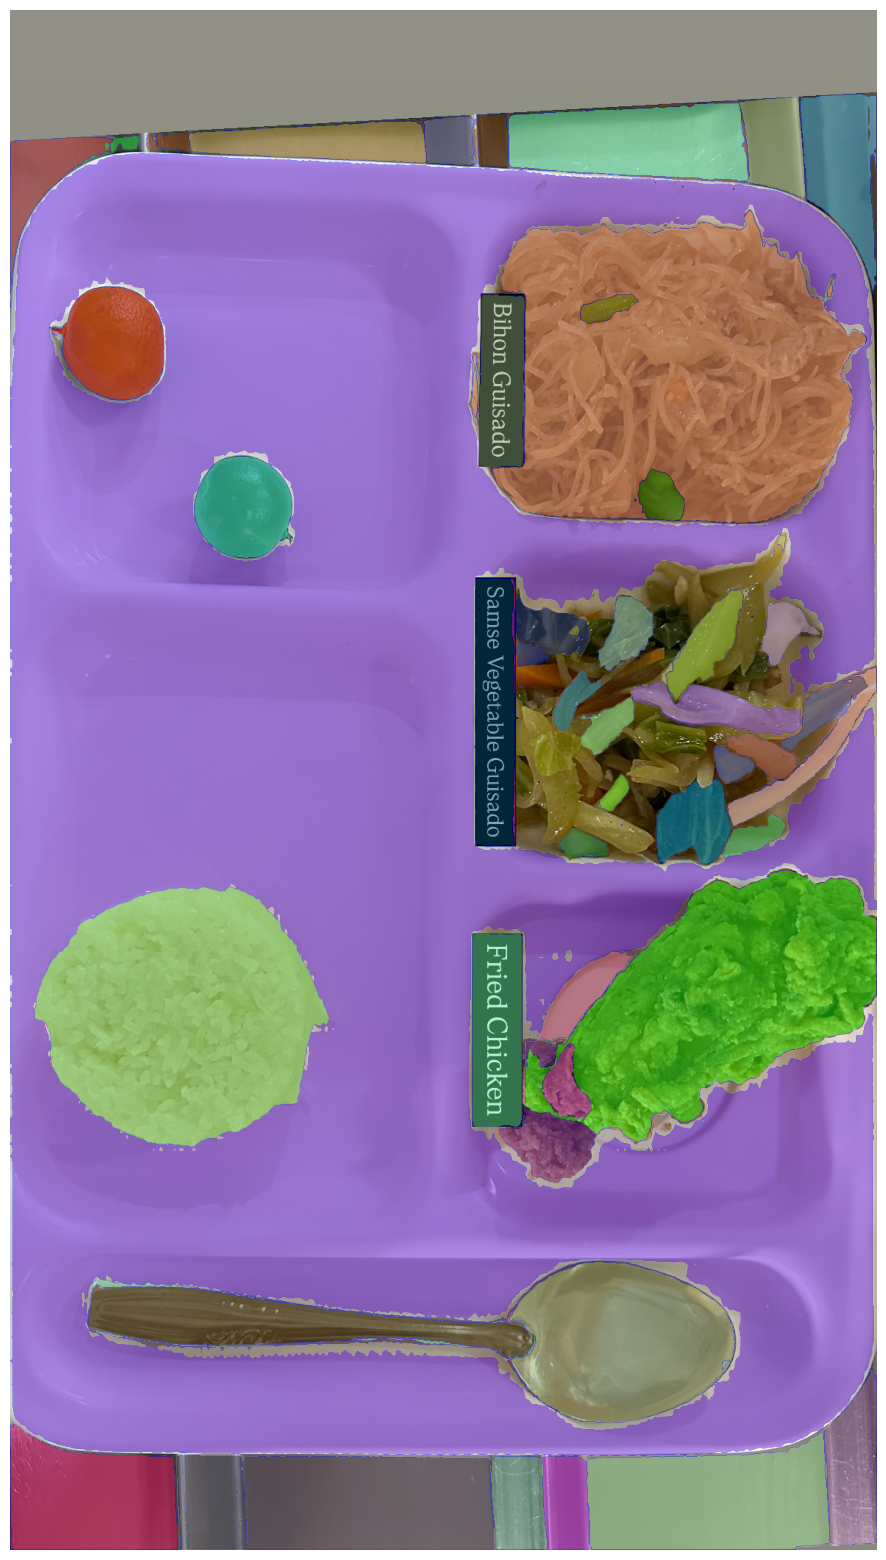

In [41]:
plt.figure(figsize=(20, 20))
plt.imshow(image)
show_anns(masks2)
plt.axis('off')
plt.show()

# Grounding DINO


In [61]:
import requests

import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from accelerate import Accelerator

In [62]:
model_id = "IDEA-Research/grounding-dino-tiny"
device = Accelerator().device

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to(device)

Loading weights:   0%|          | 0/990 [00:00<?, ?it/s]

In [50]:
image_url = "/content/April 13, 2026  Plate.jpg"
image = Image.open(image_url).convert("RGB")
text_labels = [["food serving"]]

inputs = processor(images=image, text=text_labels, return_tensors="pt").to(model.device)


In [51]:
with torch.no_grad():
    outputs = model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.4,
    text_threshold=0.3,
    target_sizes=[image.size[::-1]]
)

In [52]:
result = results[0]
for box, score, labels in zip(result["boxes"], result["scores"], result["labels"]):
    box = [round(x, 2) for x in box.tolist()]
    print(f"Detected {labels} with confidence {round(score.item(), 3)} at location {box}")

Detected food with confidence 0.537 at location [621.21, 268.26, 1164.09, 699.6]
Detected food with confidence 0.468 at location [683.08, 710.12, 1173.81, 1163.51]
Detected food with confidence 0.453 at location [662.43, 1165.96, 1175.47, 1597.01]
Detected food with confidence 0.467 at location [33.56, 1182.92, 421.21, 1551.62]


/usr/local/lib/python3.12/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:91: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


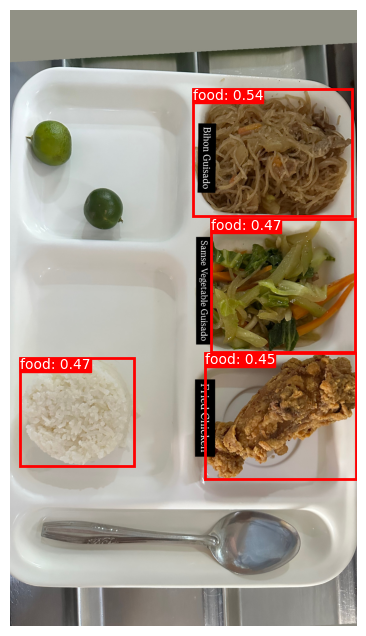

In [53]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Create a figure and axis
fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

# Loop through the detected boxes, scores, and labels
for box, score, label in zip(result["boxes"], result["scores"], result["labels"]):
    # Box format from post-processor is [xmin, ymin, xmax, ymax]
    xmin, ymin, xmax, ymax = box.tolist()
    width, height = xmax - xmin, ymax - ymin

    # Draw the rectangle (edgecolor='red' or 'lime' for visibility)
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

    # Add the text label and confidence score
    plt.text(xmin, ymin, f"{label}: {round(score.item(), 2)}",
             color='white', verticalalignment='top',
             bbox={'color': 'red', 'pad': 0})

plt.axis('off') # Hide the grid and axes
plt.show()

In [100]:
image_url = "/content/April 13, 2026  Plate.jpg"
image = Image.open(image_url).convert("RGB")
text_labels = [["Fruit", "Rice", "Fried Chicken", "Samse Vegetable Gulsado", "Bihon  Guuisado"]]

inputs = processor(images=image, text=text_labels, return_tensors="pt").to(model.device)


In [101]:
with torch.no_grad():
    outputs = model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.4,
    text_threshold=0.3,
    target_sizes=[image.size[::-1]]
)

In [102]:
result = results[0]
for box, score, labels in zip(result["boxes"], result["scores"], result["labels"]):
    box = [round(x, 2) for x in box.tolist()]
    print(f"Detected {labels} with confidence {round(score.item(), 3)} at location {box}")

Detected fried chicken with confidence 0.758 at location [661.87, 1165.17, 1174.9, 1597.24]
Detected rice with confidence 0.678 at location [34.0, 1184.5, 425.01, 1551.16]
Detected rice with confidence 0.447 at location [622.21, 268.92, 1164.22, 699.79]
Detected fruit with confidence 0.489 at location [247.26, 601.78, 387.45, 748.68]
Detected sam vegetable gulsado with confidence 0.415 at location [684.01, 714.69, 1107.22, 1159.61]


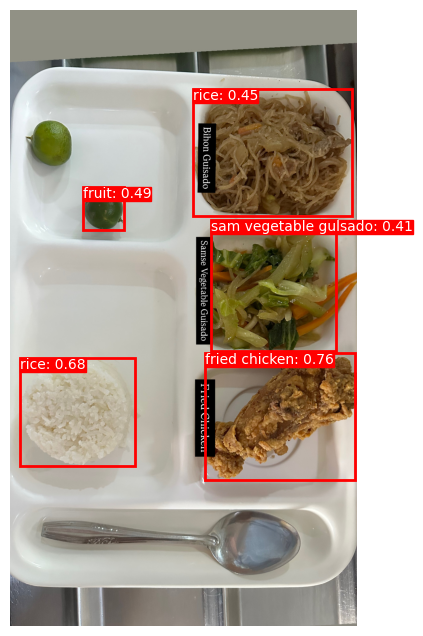

In [103]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Create a figure and axis
fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

# Loop through the detected boxes, scores, and labels
for box, score, label in zip(result["boxes"], result["scores"], result["labels"]):
    # Box format from post-processor is [xmin, ymin, xmax, ymax]
    xmin, ymin, xmax, ymax = box.tolist()
    width, height = xmax - xmin, ymax - ymin

    # Draw the rectangle (edgecolor='red' or 'lime' for visibility)
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

    # Add the text label and confidence score
    plt.text(xmin, ymin, f"{label}: {round(score.item(), 2)}",
             color='white', verticalalignment='top',
             bbox={'color': 'red', 'pad': 0})

plt.axis('off') # Hide the grid and axes
plt.show()

In [104]:
image_url = "/content/April 13, 2026  Plate unlabeled.JPG"
image = Image.open(image_url).convert("RGB")
text_labels = [["Fruit", "Rice", "Fried Chicken", "Vegetables", "Bihon  Stew"]]

inputs = processor(images=image, text=text_labels, return_tensors="pt").to(model.device)


In [105]:
with torch.no_grad():
    outputs = model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.4,
    text_threshold=0.3,
    target_sizes=[image.size[::-1]]
)

In [106]:
result = results[0]
for box, score, labels in zip(result["boxes"], result["scores"], result["labels"]):
    box = [round(x, 2) for x in box.tolist()]
    print(f"Detected {labels} with confidence {round(score.item(), 3)} at location {box}")

Detected chicken with confidence 0.723 at location [663.1, 1165.38, 1175.54, 1597.58]
Detected rice with confidence 0.703 at location [34.33, 1183.87, 432.45, 1551.43]
Detected fruit with confidence 0.643 at location [247.79, 603.0, 386.17, 748.2]
Detected fruit with confidence 0.585 at location [52.41, 372.75, 211.45, 531.68]
Detected vegetables with confidence 0.523 at location [683.83, 710.59, 1173.84, 1162.06]
Detected bihon stew with confidence 0.415 at location [623.35, 268.84, 1164.3, 700.35]


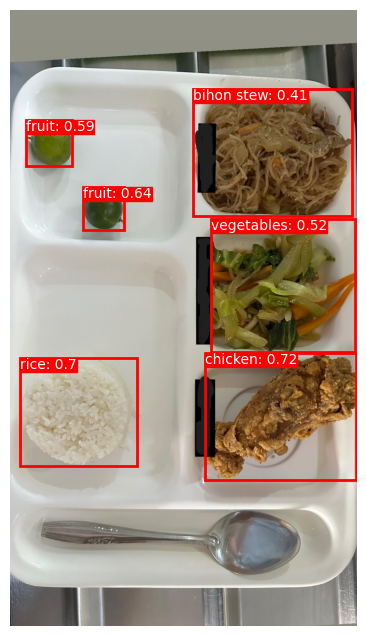

In [107]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Create a figure and axis
fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

# Loop through the detected boxes, scores, and labels
for box, score, label in zip(result["boxes"], result["scores"], result["labels"]):
    # Box format from post-processor is [xmin, ymin, xmax, ymax]
    xmin, ymin, xmax, ymax = box.tolist()
    width, height = xmax - xmin, ymax - ymin

    # Draw the rectangle (edgecolor='red' or 'lime' for visibility)
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

    # Add the text label and confidence score
    plt.text(xmin, ymin, f"{label}: {round(score.item(), 2)}",
             color='white', verticalalignment='top',
             bbox={'color': 'red', 'pad': 0})

plt.axis('off') # Hide the grid and axes
plt.show()